# 53 · Project 4: Go1 walks: PPO in MJX, domain randomization, stress tests (Colab GPU)

Train once (~25 min); weights are saved to Google Drive (`MyDrive/vla_course/`) and every later run loads them. Rollouts are single compiled `lax.scan` calls, push tests run all seeds in parallel, videos use the robot-tracking cameras.

In [2]:
!pip install -q "playground==0.2.0" "jax[cuda12]==0.7.2" "flax==0.11.2" "orbax-checkpoint==0.11.22" mediapy
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"

In [ ]:
import os, time, pickle, functools, jax, jax.numpy as jp, numpy as np, mujoco, mediapy as media, matplotlib.pyplot as plt
from brax.training.acme import running_statistics
from brax.training.agents.ppo import train as ppo
from brax.training.agents.ppo import networks as ppo_networks
from mujoco_playground import registry, wrapper
from mujoco_playground.config import locomotion_params

ENV = "Go1JoystickFlatTerrain"
NUM_TIMESTEPS = 60_000_000          # ~25 min on a T4; 30_000_000 (~13 min) already walks
ENV_OBJ = registry.load(ENV)
NET_CFG = dict(locomotion_params.brax_ppo_config(ENV).network_factory)

from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/vla_course"
os.makedirs(SAVE_DIR, exist_ok=True)

def train(randomize, num_timesteps=NUM_TIMESTEPS):
    p = locomotion_params.brax_ppo_config(ENV); p.num_timesteps = num_timesteps
    params = dict(p); params.pop("network_factory")
    curve, t0 = [], time.time()
    def progress(step, metrics):
        curve.append((step, float(metrics["eval/episode_reward"])))
        print(f"step {step:>12,}  reward {curve[-1][1]:8.2f}  {time.time() - t0:6.0f}s")
    cfg = registry.get_default_config(ENV)
    _, prm, _ = ppo.train(environment=registry.load(ENV, config=cfg), eval_env=registry.load(ENV, config=cfg),
                          wrap_env_fn=wrapper.wrap_for_brax_training, progress_fn=progress,
                          randomization_fn=registry.get_domain_randomizer(ENV) if randomize else None,
                          network_factory=functools.partial(ppo_networks.make_ppo_networks, **NET_CFG), **params)
    return prm, np.array(curve)

def save_params(params, name):
    with open(f"{SAVE_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(jax.tree_util.tree_map(np.asarray, params), f)
    print("saved", f"{SAVE_DIR}/{name}.pkl")

def get_policy(name, randomize):
    """Load saved weights if they exist, otherwise train once and save them."""
    path = f"{SAVE_DIR}/{name}.pkl"
    if os.path.exists(path):
        params = pickle.load(open(path, "rb")); print("loaded", path, "-- no training needed")
    else:
        params, curve = train(randomize); save_params(params, name)
        plt.figure(figsize=(6, 3.5)); plt.plot(curve[:, 0], curve[:, 1]); plt.xlabel("env steps"); plt.ylabel("eval reward"); plt.title(name); plt.show()
    nets = ppo_networks.make_ppo_networks(ENV_OBJ.observation_size, ENV_OBJ.action_size,
                                          preprocess_observations_fn=running_statistics.normalize, **NET_CFG)
    return ppo_networks.make_inference_fn(nets)(params, deterministic=True)

def make_rollout(policy):
    """A whole episode as ONE compiled call (lax.scan). commands: (T, 3) [vx, vy, yaw_rate]; pushes: (T, 3) velocity kicks.
    Returns (single-episode fn, batched-over-seeds fn)."""
    env = ENV_OBJ
    def episode(key, commands, pushes):
        state = env.reset(key)
        def body(state, inp):
            cmd, push = inp
            state = state.replace(info={**state.info, "command": cmd})
            state = state.replace(data=state.data.replace(qvel=state.data.qvel.at[:3].add(push)))
            act, _ = policy(state.obs, key)
            state = env.step(state, act)
            return state, (state.data.qpos, env.get_local_linvel(state.data)[:2], state.done)
        return jax.lax.scan(body, state, (commands, pushes))[1]
    return jax.jit(episode), jax.jit(jax.vmap(episode, in_axes=(0, None, None)))

def render(qpos, camera="track", height=360, width=640, every=2):
    """Copy the trajectory off the GPU once, then render with plain MuJoCo (much faster than env.render)."""
    m = ENV_OBJ.mj_model; d = mujoco.MjData(m); frames = []
    with mujoco.Renderer(m, height, width) as r:
        for q in np.asarray(qpos)[::every]:
            d.qpos[:] = q; mujoco.mj_forward(m, d); r.update_scene(d, camera=camera); frames.append(r.render())
    return frames

def schedule(segments):
    """[(steps, [vx, vy, yaw]), ...] -> (T, 3) command array."""
    return jp.concatenate([jp.tile(jp.array(c, dtype=jp.float32), (n, 1)) for n, c in segments])

Mounted at /content/drive


Module mujoco.mjx.warp.ffi bc5cef1 load on device 'cuda:0' took 1.48 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.smooth 6847a03 load on device 'cuda:0' took 2.17 ms  (cached)
Module _nxn_broadphase__locals__kernel_0dcff9d2 0dcff9d load on device 'cuda:0' took 1.17 ms  (cached)
Module _nxn_broadphase__locals__kernel_0dcff9d2 1c34f5a load on device 'cuda:0' took 1.53 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_25442a3d 25442a3 load on device 'cuda:0' took 1.44 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 9feb269 load on device 'cuda:0' took 1.17 ms  (cached)
Module _friction_dof__locals__kernel_451d1ac6 451d1ac load on device 'cuda:0' took 1.13 ms  (cached)
Module _limit_slide_hinge__locals__kernel_fb6bdfd1 fb6bdfd load on device 'cuda:0' took 1.23 ms  (cached)
Module _efc_contact_init__locals__kernel_5b9c0428 5b9c042 load on device 'cuda:0' took 1.16 ms  (cached)
Module _efc_contact_jac_dense__locals__kernel_082f2d4

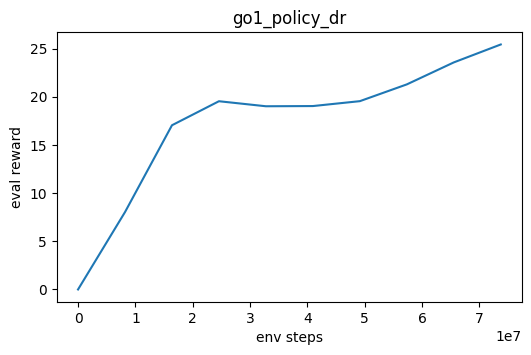

In [ ]:
policy_dr = get_policy("go1_policy_dr", randomize=True)
run_dr, run_dr_batch = make_rollout(policy_dr)

In [ ]:
T = 400
cmds, no_push = schedule([(T, [1.0, 0.0, 0.0])]), jp.zeros((T, 3))
t0 = time.time(); qpos, vel, done = run_dr(jax.random.PRNGKey(0), cmds, no_push); qpos.block_until_ready()
print(f"400-step rollout: {time.time() - t0:.1f}s | command vx=1.0 -> achieved {np.asarray(vel)[100:, 0].mean():.2f} m/s | fell: {bool(np.asarray(done).any())}")
media.show_video(render(qpos), fps=1 / ENV_OBJ.dt / 2)

400-step rollout: 29.1s | command vx=1.0 -> achieved 1.02 m/s | fell: False


This browser does not support the video tag.


In [ ]:
# SHOWCASE for students: one scripted joystick session -- forward, arc left, side-step, backward, stand
show_cmds = schedule([(100, [1.0, 0.0, 0.0]), (100, [0.6, 0.0, 0.8]), (100, [0.0, 0.5, 0.0]), (100, [-0.6, 0.0, 0.0]), (80, [0.0, 0.0, 0.0])])
qpos, vel, done = run_dr(jax.random.PRNGKey(1), show_cmds, jp.zeros((len(show_cmds), 3)))
print("fell:", bool(np.asarray(done).any()))
for cam in ["track", "side"]:
    print("camera:", cam); media.show_video(render(qpos, camera=cam), fps=1 / ENV_OBJ.dt / 2)

fell: False
camera: track


This browser does not support the video tag.


camera: side


This browser does not support the video tag.


In [ ]:
# Save the showcase as an MP4 (for slides / lecture recording)
import imageio
imageio.mimsave(f"{SAVE_DIR}/go1_showcase_track.mp4", render(qpos, height=480, width=854, every=1), fps=int(1 / ENV_OBJ.dt))
print("saved", f"{SAVE_DIR}/go1_showcase_track.mp4")

/usr/lib/python3.13/subprocess.py:1922: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(


saved /content/drive/MyDrive/vla_course/go1_showcase_track.mp4


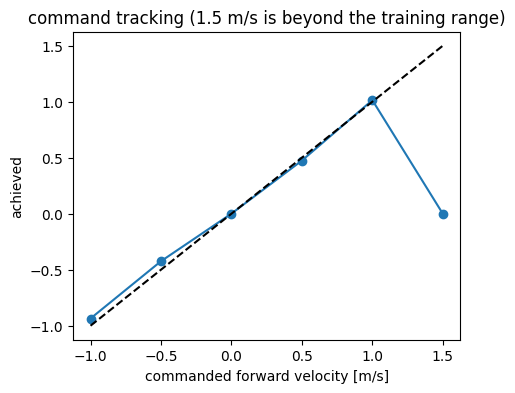

In [ ]:
# Command tracking (each speed = one compiled GPU call)
speeds = np.linspace(-1.0, 1.5, 6)
achieved = [np.asarray(run_dr(jax.random.PRNGKey(2), schedule([(300, [v, 0, 0])]), jp.zeros((300, 3)))[1])[100:, 0].mean() for v in speeds]
plt.figure(figsize=(5, 4)); plt.plot(speeds, achieved, "o-"); plt.plot(speeds, speeds, "k--")
plt.xlabel("commanded forward velocity [m/s]"); plt.ylabel("achieved"); plt.title("command tracking (1.5 m/s is beyond the training range)"); plt.show()

step            0  reward     0.00      49s
step    8,192,000  reward     7.38     252s
step   16,384,000  reward    17.35     410s
step   24,576,000  reward    19.87     563s
step   32,768,000  reward    20.16     714s
step   40,960,000  reward    21.57     862s
step   49,152,000  reward    23.24    1006s
step   57,344,000  reward    25.89    1146s
step   65,536,000  reward    27.31    1281s
step   73,728,000  reward    27.81    1416s
saved /content/drive/MyDrive/vla_course/go1_policy_nodr.pkl


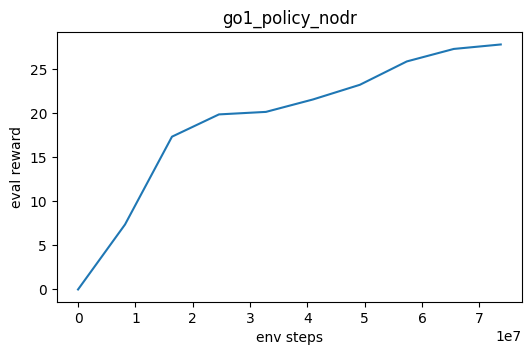

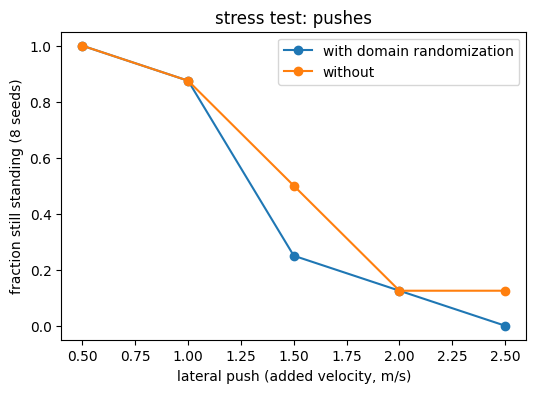

In [ ]:
# Stress test: lateral pushes, 8 seeds in parallel per push size, with vs without domain randomization
policy_nodr = get_policy("go1_policy_nodr", randomize=False)      # trains once (~25 min) if not saved yet
_, run_nodr_batch = make_rollout(policy_nodr)
T, AT = 300, 150
keys = jax.random.split(jax.random.PRNGKey(3), 8)
walk = schedule([(T, [0.5, 0, 0])])
pushes = [0.5, 1.0, 1.5, 2.0, 2.5]
surv = {"with domain randomization": [], "without": []}
for p in pushes:
    kick = jp.zeros((T, 3)).at[AT, 1].set(p)
    for name, run in [("with domain randomization", run_dr_batch), ("without", run_nodr_batch)]:
        surv[name].append(1.0 - np.asarray(run(keys, walk, kick)[2]).any(1).mean())
plt.figure(figsize=(6, 4))
for name, s in surv.items():
    plt.plot(pushes, s, "o-", label=name)
plt.xlabel("lateral push (added velocity, m/s)"); plt.ylabel("fraction still standing (8 seeds)"); plt.legend(); plt.title("stress test: pushes"); plt.show()